# **Spectral Modularity Clustering on the Karate Club Graph**

## 1. Contains the necessary libraries, initial graph and other objects to be used in this code.

In [30]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

G = nx.karate_club_graph()
H = G.copy()
f,e = 0, 1
Metrics_Name = ["Degree Centrality", "Betweenness Centrality",
                "Closeness Centrality", "Clustering Coefficent" ]
Colour_Name = [ "#FF5733","#33FF57","#3357FF","#F3FF33","#FF33F3","#33FFF3","#FFA500","#800080","#008000","#000080","#FFC0CB","#A52A2A","#FF3399","#A4CDFF","#FF00FF",
                "#800000","#808000","#008080","#4B0082","#EE82EE","#FF4500","#2E8B57","#4682B4","#D2B48C","#CD5C5C","#20B2AA","#778899","#B0C4DE","#FFFFE0","#FA8072",
                "#9932CC","#8B4513","#556B2F","#9400D3","#1E90FF" ]
Metrics_Values = np.zeros((4,34,8))

## 2. Following are the functions defined for the partitioning based on modularity.

### 2.1 Forming the Modularity Matrix B of the Karate Club Graph.

In [31]:
def Master_B (A,m):
    global Master_B
    k = np.sum(A, axis = 1)
    B = A - ((np.outer(k,k))/(2*m))
    Master_B = B

### 2.2 Forming the Modularity Matrix B for a given subgraph.

In [32]:
def Calc_B (g):
    global Master_B
    C = list(g.nodes)
    Idx = np.ix_(*(C,C))
    return Master_B[Idx]

### 2.3 Calculating the Modularity Score of a graph, and returning hard clustering vector s if the score is positive.

In [33]:
  
def Modularity (B , m):
    
    eigvalues , eigvectors = np.linalg.eigh(B)
    try:
        ev_max = np.max(eigvalues)
    except ValueError:
        ev_max = 0
    
    if ev_max > 0:
        ev_maxid = np.argmax(eigvalues)
        u = eigvectors[:,ev_maxid]
        s = ((u > 0).astype(int) * 2) - 1
        return s
    else:
        return np.zeros(1)

### 2.4 Returns the Community lists after partition, if the Modularity is positive.

In [34]:
def Partition (A,g,m):
    
    B = Calc_B(g)
    s = Modularity(B, m)
    
    if s.any() == bool(np.False_):
        C1, C2 = [], [] 
    else:
        community_dict = {node:int(val) for node, val in zip(g.nodes(), s.flatten())}
        C1, C2 = [], []
        for i in community_dict.keys():
            if community_dict[i] == 1:
                C1.append(i)
            elif community_dict[i] == -1:
                C2.append(i)
    return C1, C2

### 2.5 Forms the Subgraph object, from the Community list.

In [35]:
def Remove_Edges(A,C1,C2):
    H = G.copy()
    I = G.copy()
    J = G.copy()
    K = G.copy()
    
    H.remove_nodes_from(C1)
    I.remove_nodes_from(C2)

    J.remove_edges_from(H.edges(data=True))
    J.remove_edges_from(I.edges(data=True))
    K.remove_edges_from(J.edges)
        
    return K

### 2.6 Calculate the four Centrality Metrics value for all the nodes.
The Following Metrics are calculated:
<ul>
    <li> <b>Degree Centrality</b></li>
    <li> <b>Betweenness Centrality</b></li>
    <li> <b>Closeness Centrality</b></li>
    <li> <b>Clustering Coefficient</b></li>
<u/>

In [36]:
def Calc_Metrics(g):
    global Metrics_Name
    global f
    global Metrics_Values

    a = nx.degree_centrality(g)
    
    for i in a.keys():
        Metrics_Values[0][i][f:] = a[i]
            
    a = nx.betweenness_centrality(g)
    for i in a.keys():
        Metrics_Values[1][i][f:] = a[i]
            
    a = nx.closeness_centrality(g)
    for i in a.keys():
        Metrics_Values[2][i][f:] = a[i]
            
    a = nx.clustering(g)
    for i in a.keys():
        Metrics_Values[3][i][f:] = a[i]
            
    f += 1

### 2.7 Plots the Graph after each Partitioning.

In [37]:
def Plot(g):
    global e
    global pos
    global H
    global Colour_Name
    global Colours
    global Components
    
    H1 = H.copy()
    H2 = H.copy()
    H3 = H.copy()
    g1 = g.copy()
       
    H1.remove_nodes_from(g1)

    H2.remove_edges_from(g1.edges(data=True))
    H2.remove_edges_from(H1.edges(data=True))
    H3.remove_edges_from(H2.edges)
    
    if nx.utils.graphs_equal(H3,H):
        return
    H = H3
    
    Colours = ["Grey"]*34
    z=0
    Components = list(nx.connected_components(H))
    for i in Components:
        for j in i:
            Colours[j] = Colour_Name[z]
        z += 1    
        
    plt.figure(e, figsize=(10,8))
    plt.title(f"After {e-1}th Partitioning")
    nx.draw_networkx_nodes(H3, pos ,node_color = Colours, node_size=300)
    nx.draw_networkx_edges(H3, pos, alpha=0.5)
    nx.draw_networkx_labels(H3, pos, font_size=10)
    e += 1
    

### 2.8 The main Recursive Code that operates on the Karate Club Graph.
#### Recursive calls on each subgraph , until all possible communities are formed.

In [38]:
def Recursive_Modularity_Clustering(G,m):
    global e
    global pos
    global Metrics_Values

    A = nx.to_numpy_array(G, weight="none") #into numpy matrix
    C1,C2 = [],[]
    C1, C2 = Partition(A,G,m)
    if C1 == [] or C2 == []:
        return G
    else:
        K = Remove_Edges(G, C1, C2)
        Plot(K)
        
        Subg1 = K.subgraph(C1).copy()
        Subg2 = K.subgraph(C2).copy()
        
        Calc_Metrics(Subg1)
        Calc_Metrics(Subg2)
        
        subg1 = Recursive_Modularity_Clustering(Subg1,m)
        subg2 = Recursive_Modularity_Clustering(Subg2,m)
        K = nx.compose(subg1, subg2)
        
        return K
        

### 2.9 Function that initiates the Recursive Algorithm.

In [39]:
def Graph(G):
    A = nx.to_numpy_array(G, weight="none") #into numpy matrix 
    m = (np.sum(A))/2
    Master_B(A,m)
    return Recursive_Modularity_Clustering(G,m)

## 3. Zachary's Karate Club Graph.

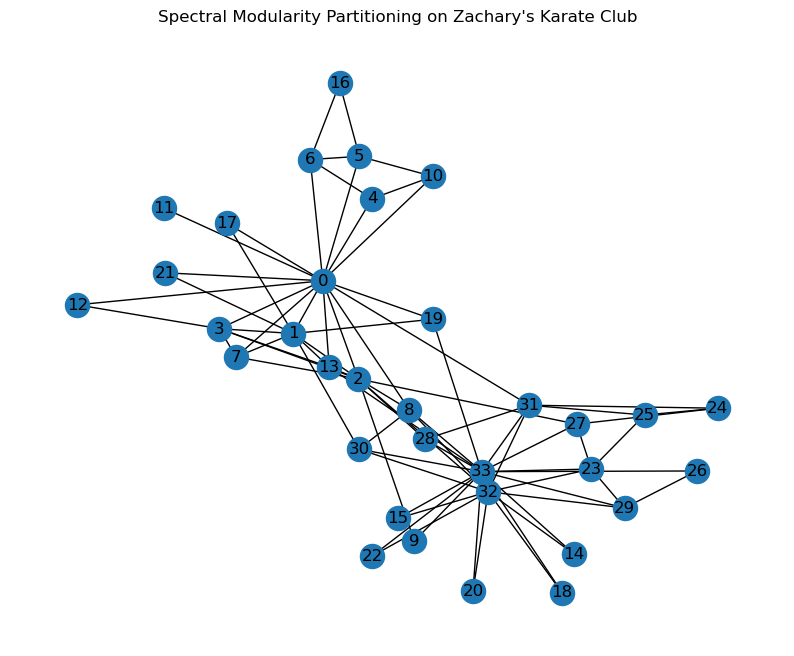

In [40]:
plt.figure(figsize=(10, 8))
plt.title("Spectral Modularity Partitioning on Zachary's Karate Club")

pos = nx.spring_layout(G, seed=42)
plt.figure(e)
nx.draw(G,pos, with_labels=True)
e += 1

## 4. Initiating the Modularity Algorithm, and Plotting graph after each partition.

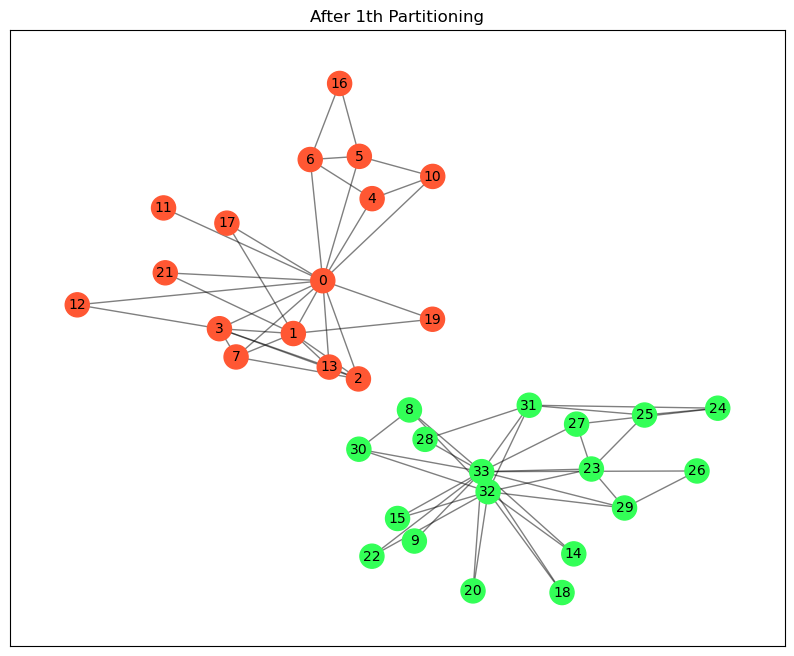

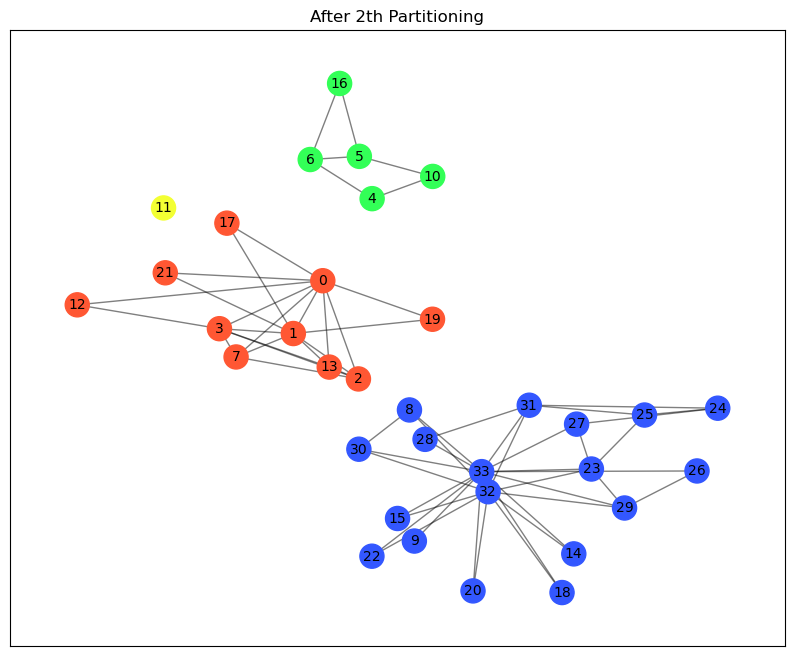

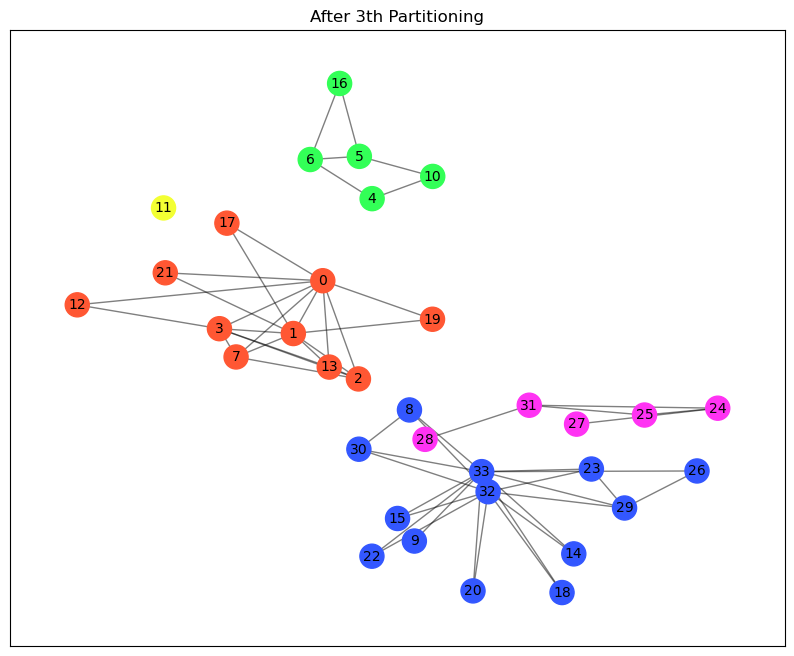

In [41]:
g = Graph(G)

## 5. The Final Commmunities and Modularity Score, after applying the Algorithm.

Final Spectral Modularity Score of the graph : 0.43014561196379375


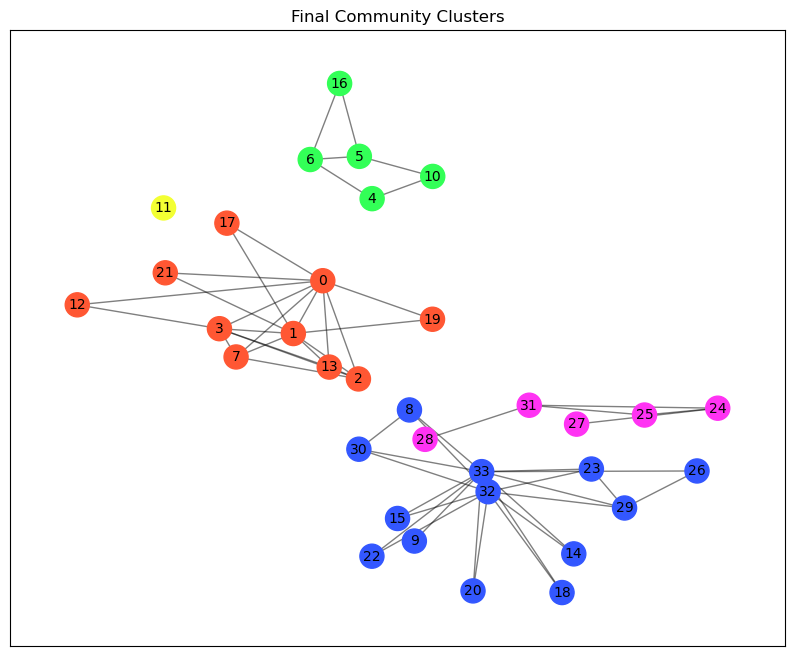

In [42]:
plt.figure(e, figsize=(10,8))
plt.title("Final Community Clusters")
nx.draw_networkx_nodes(G, pos,node_color = Colours, node_size=300)
nx.draw_networkx_edges(g, pos, alpha=0.5)
nx.draw_networkx_labels(g, pos, font_size=10)
plt.plot()
e += 1

print("Final Spectral Modularity Score of the graph :",nx.algorithms.community.modularity(G,Components))

## 6. Evolution of each Metrics Value after each iteration, across all nodes.

[0, 11, 33]
[0, 11, 33, 1]
[0, 11, 33, 1, 32]
No. of nodes =  5
[33]
[33, 24, 31]
[33, 24, 31, 0]
No. of nodes =  4
[0, 33]
[0, 33, 1]
[0, 33, 1, 32]
No. of nodes =  4
[7, 8, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 25, 26, 30]
[7, 8, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 25, 26, 30, 2]
[7, 8, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 25, 26, 30, 2, 3, 29]
No. of nodes =  20


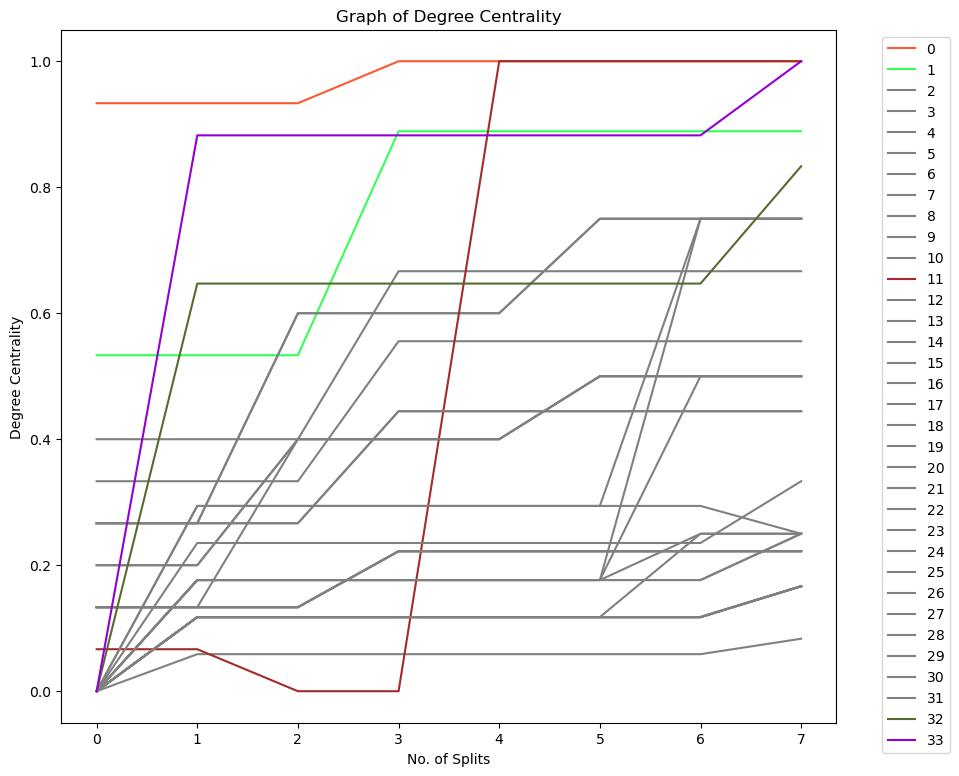

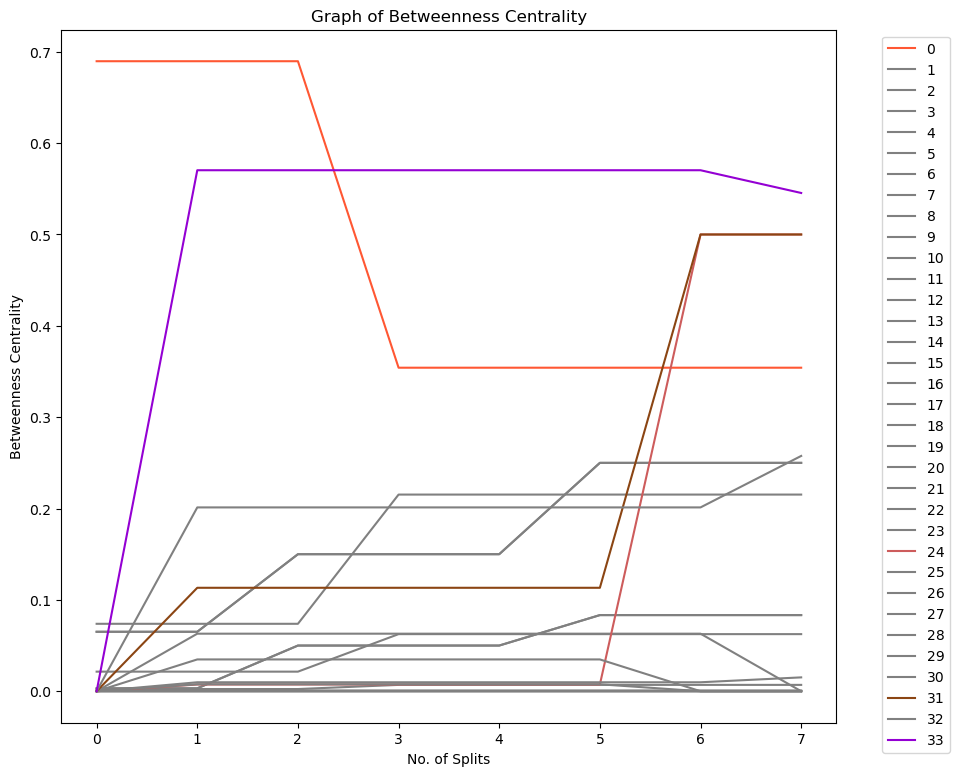

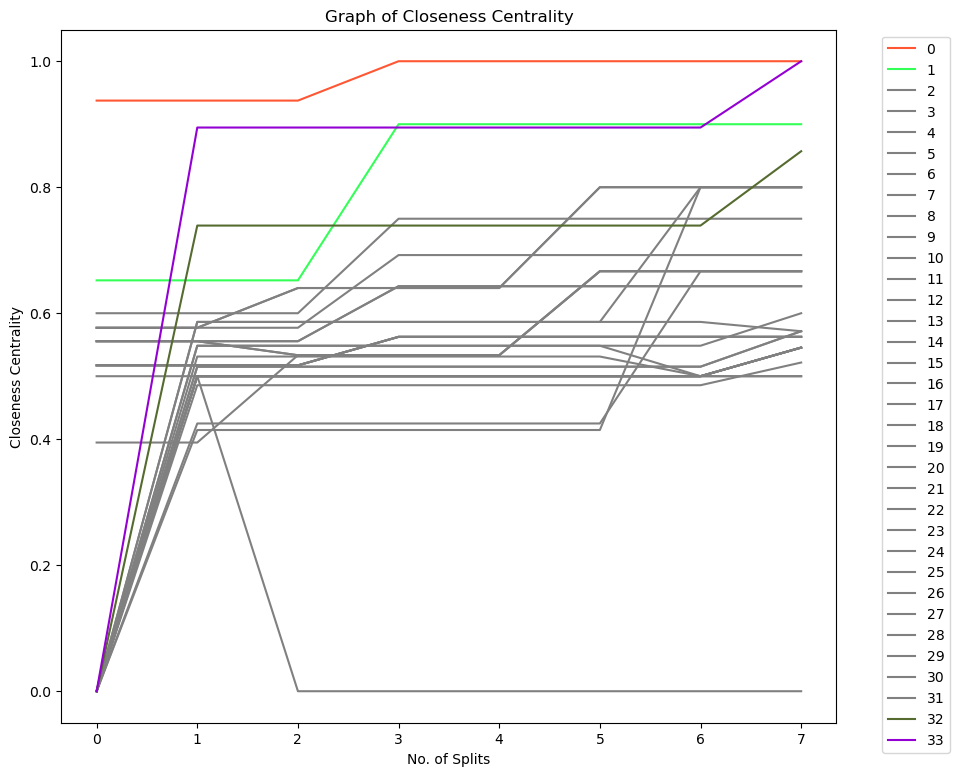

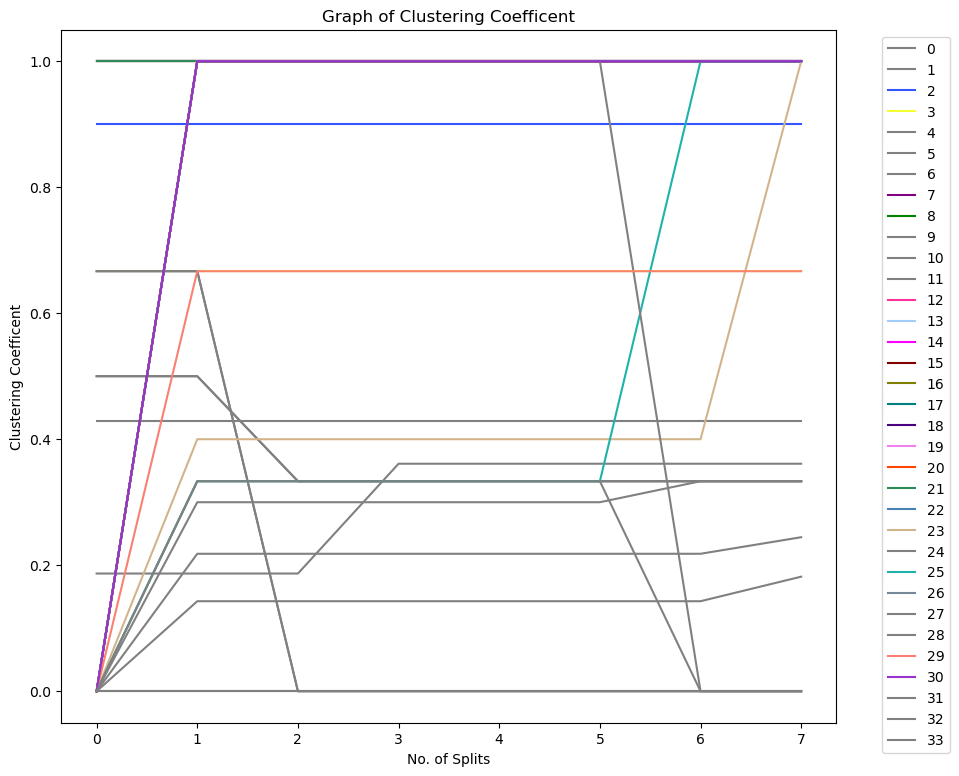

In [74]:
x = [x for x in range(0,8)]

for j in [0,1,2,3]:
    plt.figure(e, figsize=(10, 9))
    e += 1
    plt.title(f"Graph of {Metrics_Name[j]}")
    plt.xlabel("No. of Splits")
    plt.ylabel(Metrics_Name[j])
    
    k = np.array(Metrics_Values[j][:,-1])
    l = []
    for i in range(0,3):
        q = np.argmax(k)
        p = k[q]
        l = l + np.where(k == p)[0].tolist()
        for m in l:
            k[m] = 0
        print(l)
    
    print("No. of nodes = ", len(l))
    Colour_Palette = ["Grey"]*34
    for i in l:
        Colour_Palette[i] = str(Colour_Name[i])
        
    for i in range(0,34):
        plt.plot(x, list(Metrics_Values[j][i]),color = Colour_Palette[i], label= str(i))
        plt.legend(bbox_to_anchor=(1.05, 1), loc="best")

## 7. Discussion of Metrics and its Evolution across Iterations

### The Following Metrics were calculated:
<ul>
    <li> <b><i>Degree Centrality</i></b> : Measures the fraction of nodes that are directly connected to i. Nodes with high degree
centrality are immediate hubs with many direct links.</li><br>
    <li> <b><i>Betweenness Centrality</i></b> : Counts how often node i lies on shortest paths between other nodes. Nodes with high
betweenness act as bridges or brokers, controlling information flow between different parts
of the network.</li><br>
    <li> <b><i>Closeness Centrality</i></b> : Inverse of the average shortest-path distance from i to all other nodes. A high closeness
score indicates that a node can reach all others quickly, making it a good “spreader” in
the network.</li><br>
    <li> <b><i>Clustering Coefficient</i></b> : Fraction of a node’s neighbors that are also connected to each other. High clustering
indicates that i is embedded in a tightly-knit group.</li>
<u/>

### 7.1 Degree Centrality


Degree centrality denotes the number of immediate neighbors of a node, i.e. which are only one edge away from the node. It is simple. It can be interpreted as the number of walk of length one starting at the considered node. It measures the local influence of a node. From the given graph and Line graph, <b>Nodes 0, 1, 11, 32, 33</b> have the bigger values in the final clusters. After each split of coomunity, nodes having direct edges to these nodes stay constant but the total number of nodes decrease in each subsequent graphs. Meaning each split takes away the edges have least connection to these nodes and its neighbours. Thus creating communities with less inter-connections and more intra-connections.

### 7.2 Betweenness Centrality

Betweenness centrality defines the influence of a node based on the number of shortest paths between every pair of nodes that passes through that node. It basically tries to identify the influence of a node in terms of information flow through the network. A node with higher betweenness centrality would have more control over the network because more information flows through it. In the graph, <b>Nodes 0, 24, 31, 33</b> have the final largest values. Throughout the splitting, these nodes remain central to the graph and emerge as "Communicators" of the community, given their power in flow of information.

### 7.3 Closeness Centrality

Closeness Centrality (or Closeness) of a node is a measure of centrality in a network, calculated as the reciprocal of the sum of the length of the shortest paths between the node and all other nodes in the graph. Thus, the more central a node is, the closer it is to all other nodes.<b>Nodes 0, 1, 32, 33</b>, arise more Central than other nodes. They have the most shortest connections between all the nodes within the community. Each splitting increases the centrality of their role in the community (Even visually). Thus arising as the "Natural Leaders" of each community.

### 7.4 Clustering Coefficient

Clustering Coefficient is a measure of the degree to which nodes in a graph tend to cluster together. Some nodes tend to create tightly knit groups characterised by a relatively high density of ties. <b>Nodes 2, 3, 7, 8, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 25, 26, , 29, 30</b> are such examples. After each splitting, the edges to the neighbours which dont connect to other neighbours are removed and thus, in the final community, all their neighbours are also neighbours of each other. The high number of nodes here, having the highest values is due to the fact,the clustering algorithm was so precise and perfect that the resultant communities are all tightly knit or, in other words, have a lot of within-cluster edges.

## 8. References

<ul>
    <li><cite>“Modularity and community structure in networks” - <b>PNAS 103(23):8577–8582 - Newman (2006)</b></cite></li>
    <li>Stack Oveflow</li>
    <li>GeeksforGeeks</li>
    <li>Google AI Overview (Only used for NetWorkX Documentation otherwise <b>AI Free Code </b>{ Hence the Un-Optimized Code! })</li>
</ul>